# Notification Fatigue Optimization: Predictive Modeling

**Goal:** Evaluate time-gated click and engagement models on a future holdout. Several simulator-feature creation times remain unverified; a restricted-feature sensitivity is reported below. Churn modeling is attempted only if its label is valid. Results from this synthetic dataset are predictive associations, not causal effects.

## Imports

Load the approved modeling and evaluation tools.

In [1]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

In [ ]:
# Self-contained analysis helpers integrated from the former phase modules.

# Only the dependency closure used by this notebook is included.

OBSERVATION_END = pd.Timestamp("2026-04-01")

KEY = ["user_id", "event_timestamp"]

CHURN_METADATA = [
    "source_churn_target", "source_no_app_open_next_30d", "churn_status",
    "churn_witness_event_timestamp", "churn_witness_latest_open",
    "churn_window_complete_calendar", "churn_model_eligible",
]

def validate_churn_labels(raw, observation_end=OBSERVATION_END):
    """Retain only evidence-backed negatives; never infer inactivity from silence."""
    frame = raw.copy().reset_index(drop=True)
    frame["event_timestamp"] = pd.to_datetime(frame["event_timestamp"], errors="raise")
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError("Churn evidence requires unique, nonmissing event keys")
    if "source_churn_target" in frame:
        raise ValueError("Pass immutable raw events, not an already validated table")
    frame["source_churn_target"] = frame["churn_target"]
    frame["source_no_app_open_next_30d"] = frame["no_app_open_next_30d"]
    witness = pd.Series(pd.NaT, index=frame.index, dtype="datetime64[ns]")
    for _, group in frame.groupby("user_id", sort=False):
        opens = np.sort(group.loc[group["app_opened_24h"].eq(True), "event_timestamp"].to_numpy())
        times = group["event_timestamp"].to_numpy()
        # A later event strictly more than 24h after t avoids overlap ambiguity.
        # Its entire possible open interval must lie inside (t, t + 30d].
        positions = np.searchsorted(opens, times + np.timedelta64(1, "D"), side="right")
        available = positions < len(opens)
        selected = np.full(len(group), np.datetime64("NaT"), dtype="datetime64[ns]")
        selected[available] = opens[positions[available]]
        inside = available & (selected + np.timedelta64(1, "D") <= times + np.timedelta64(30, "D"))
        selected[~inside] = np.datetime64("NaT")
        witness.loc[group.index] = selected
    frame["churn_witness_event_timestamp"] = witness
    frame["churn_witness_latest_open"] = witness + pd.Timedelta(days=1)
    mature = frame["event_timestamp"] + pd.Timedelta(days=30) <= pd.Timestamp(observation_end)
    frame["churn_window_complete_calendar"] = mature
    source_missing = frame[["source_churn_target", "source_no_app_open_next_30d"]].isna().any(axis=1)
    supported = mature & ~source_missing & witness.notna()
    frame["churn_status"] = "unverified_incomplete_activity_history"
    frame.loc[~mature, "churn_status"] = "censored_window"
    frame.loc[source_missing, "churn_status"] = "source_missing_preserved"
    frame.loc[supported, "churn_status"] = "verified_future_open_negative"
    corrected = pd.Series(pd.NA, index=frame.index, dtype="Float64")
    corrected.loc[supported] = 0.0
    frame["churn_target"] = corrected
    frame["no_app_open_next_30d"] = corrected.copy()
    # Observing a subset of negatives does not create a representative risk set.
    frame["churn_model_eligible"] = False
    assert_validated_churn(frame)
    return frame

def assert_validated_churn(frame):
    """Fail closed on unverified targets, positive claims, or missing witnesses."""
    required = CHURN_METADATA + ["churn_target", "no_app_open_next_30d"]
    if not set(required).issubset(frame.columns):
        raise ValueError("Unvalidated churn labels: use load_events()")
    observed = frame["churn_target"].notna()
    if frame.loc[observed, "churn_target"].ne(0).any():
        raise ValueError("Positive churn cannot be established from incomplete activity")
    if frame["churn_model_eligible"].any():
        raise ValueError("No complete activity-history population is available")
    if not frame["churn_target"].equals(frame["no_app_open_next_30d"]):
        raise ValueError("Canonical churn columns disagree")
    if not frame.loc[observed, "churn_status"].eq("verified_future_open_negative").all():
        raise ValueError("Unverified label cannot be retained")
    t = pd.to_datetime(frame.loc[observed, "event_timestamp"])
    w = pd.to_datetime(frame.loc[observed, "churn_witness_event_timestamp"])
    if not ((w > t + pd.Timedelta(days=1)) & (w + pd.Timedelta(days=1) <= t + pd.Timedelta(days=30))).all():
        raise ValueError("Churn witness outside conservative future-activity window")
    if frame.loc[frame["source_churn_target"].isna(), "churn_target"].notna().any():
        raise ValueError("Source missingness must be preserved")

def churn_training_data(frame):
    """Block population modeling until complete independent activity is supplied."""
    assert_validated_churn(frame)
    raise ValueError("Churn modeling blocked: incomplete activity history and evidence-selected negatives")

def load_events(project_dir):
    """Load original events through the mandatory churn-validation boundary."""
    return validate_churn_labels(pd.read_csv(Path(project_dir) / "data/raw/notification_events.csv"))

SPLIT = pd.Timestamp("2026-03-01")

RESPONSE_WINDOW = pd.Timedelta(hours=24)

def validated_timestamps(frame):
    """Reject malformed, absent, or timezone-mixed source clocks."""
    stamps = pd.to_datetime(frame["event_timestamp"], errors="raise")
    if stamps.isna().any() or not isinstance(stamps.dtype, np.dtype) or stamps.dtype.kind != "M":
        raise ValueError("Event timestamps must be complete local naive datetimes")
    if "event_date" in frame and not pd.to_datetime(frame["event_date"], errors="raise").eq(stamps.dt.normalize()).all():
        raise ValueError("event_date disagrees with event_timestamp")
    if "hour_local" in frame and not frame["hour_local"].eq(stamps.dt.hour).all():
        raise ValueError("hour_local disagrees with event_timestamp")
    return stamps

def temporal_masks(frame, split=SPLIT, observation_end=OBSERVATION_END):
    """Use completed 24-hour responses at the as-of boundary; no implicit complement test."""
    stamps = validated_timestamps(frame)
    split, observation_end = pd.Timestamp(split), pd.Timestamp(observation_end)
    if split >= observation_end:
        raise ValueError("Split must precede observation end")
    train = stamps.lt(split) & stamps.add(RESPONSE_WINDOW).le(split)
    test = stamps.ge(split) & stamps.add(RESPONSE_WINDOW).le(observation_end)
    if (train & test).any() or (train & stamps.ge(split)).any() or (test & stamps.lt(split)).any():
        raise AssertionError("Temporal partitions overlap")
    return train, test


The models are deliberately simple and interpretable.

## Configuration

Use a fixed future holdout and deterministic model seed.

In [2]:
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

user_path = project_dir / "data" / "raw" / "users.csv"
event_path = project_dir / "data" / "raw" / "notification_events.csv"

split_date = pd.Timestamp("2026-03-01")
random_state = 42
print(f"Training events occur before: {split_date.date()}")
print(f"Random state: {random_state}")

Training events occur before: 2026-03-01
Random state: 42


The as-of March 1 training set includes only responses whose full 24-hour window ended by the split. The March holdout also requires a completed window by the exclusive April 1 source-calendar boundary. A recorded extraction/ingestion timestamp is unavailable, so calendar maturity is a conservative eligibility rule, not proof of actual label arrival.

## Data Cleaning and Preprocessing

Load, parse, join, and restrict response modeling to delivered notification opportunities.

In [3]:
users = pd.read_csv(user_path)
events = load_events(project_dir)
events["event_timestamp"] = pd.to_datetime(events["event_timestamp"], errors="raise")

model_data = events.loc[events["delivered"]].merge(
    users,
    on="user_id",
    how="left",
    validate="many_to_one",
)

Conditioning on delivery gives every modeled row a valid response opportunity.

### Shape, nulls, duplicates, types, and range

Repeat the required quality checks on the modeling population.

In [4]:
print(f"Model rows: {model_data.shape[0]:,}")
print(f"Model columns: {model_data.shape[1]:,}")
print("Missing values:")
display(model_data.isna().sum().loc[lambda values: values.gt(0)].to_frame("missing_rows"))
print(f"Duplicate event keys: {model_data.duplicated(['user_id', 'event_timestamp']).sum():,}")

info_buffer = io.StringIO()
model_data.info(buf=info_buffer)
print(info_buffer.getvalue())
display(model_data["fatigue_before_send"].describe().to_frame())

Model rows: 59,341
Model columns: 39
Missing values:


,missing_rows
suppression_reason,59341
no_app_open_next_30d,29566
churn_target,29566
source_churn_target,19217
source_no_app_open_next_30d,19217
churn_witness_event_timestamp,20789
churn_witness_latest_open,20789


Duplicate event keys: 0
<class 'pandas.DataFrame'>
RangeIndex: 59341 entries, 0 to 59340
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   user_id                         59341 non-null  int64         
 1   event_timestamp                 59341 non-null  datetime64[us]
 2   channel                         59341 non-null  str           
 3   notification_type               59341 non-null  str           
 4   content_relevance               59341 non-null  float64       
 5   personalized                    59341 non-null  bool          
 6   notifications_prior_24h         59341 non-null  int64         
 7   notifications_prior_7d          59341 non-null  int64         
 8   notifications_prior_30d         59341 non-null  int64         
 9   fatigue_before_send             59341 non-null  float64       
 10  inactive_days_streak            59341 non-null  int64    

,fatigue_before_send
count,59341.000000
mean,0.115668
std,0.057874
min,0.000127
25%,0.072024
50%,0.111065
75%,0.153494
max,0.401281


Future churn fields are missing for censored or unverified rows, but click and engagement features and targets remain complete.

## Column Description

Separate candidate-time features from post-event fields. Timing-ambiguous same-day activity is excluded conservatively.

In [5]:
categorical_features = [
    "channel",
    "notification_type",
    "user_segment",
    "preferred_channel",
]
numeric_features = [
    "content_relevance",
    "personalized",
    "notifications_prior_24h",
    "notifications_prior_7d",
    "notifications_prior_30d",
    "fatigue_before_send",
    "inactive_days_streak",
    "hour_local",
    "tenure_days_at_start",
    "baseline_activity_probability",
    "engagement_propensity",
    "fatigue_sensitivity",
]
feature_columns = categorical_features + numeric_features

print("Categorical pre-decision features:", categorical_features)
print("Numeric pre-decision features:", numeric_features)
print("Excluded timing-ambiguous field: app_active_on_event_day")
print("Excluded post-event fields: all response targets and fatigue_after_event")

Categorical pre-decision features: ['channel', 'notification_type', 'user_segment', 'preferred_channel']
Numeric pre-decision features: ['content_relevance', 'personalized', 'notifications_prior_24h', 'notifications_prior_7d', 'notifications_prior_30d', 'fatigue_before_send', 'inactive_days_streak', 'hour_local', 'tenure_days_at_start', 'baseline_activity_probability', 'engagement_propensity', 'fatigue_sensitivity']
Excluded timing-ambiguous field: app_active_on_event_day
Excluded post-event fields: all response targets and fatigue_after_event


The feature list uses only baseline, candidate, and explicitly labeled prior/before values under the timing assumption documented in Notebook 01.

## EDA: Targets and split

Inspect target prevalence and sample sizes in each time period before fitting.

Incomplete training windows excluded: 654
Incomplete holdout windows excluded at April 1 calendar boundary: 607


,rows,click_rate,engagement_rate
Train,38831,0.321779,0.361129
Future test,19249,0.326666,0.365162


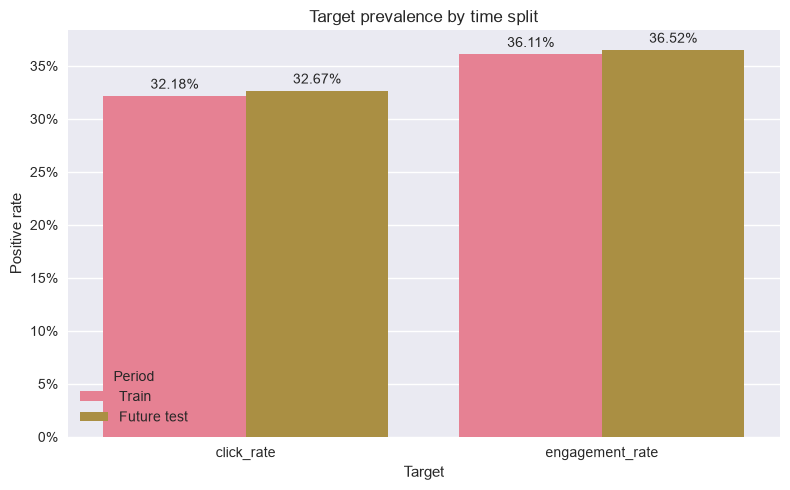

In [6]:
train_mask, test_mask = temporal_masks(model_data, split_date)
excluded_pre_split = (model_data["event_timestamp"] < split_date) & ~train_mask
excluded_final_day = (model_data["event_timestamp"] >= split_date) & ~test_mask
print(f"Incomplete training windows excluded: {excluded_pre_split.sum():,}")
print(f"Incomplete holdout windows excluded at April 1 calendar boundary: {excluded_final_day.sum():,}")

split_summary = pd.DataFrame({
    "rows": [train_mask.sum(), test_mask.sum()],
    "click_rate": [
        model_data.loc[train_mask, "clicked_24h"].mean(),
        model_data.loc[test_mask, "clicked_24h"].mean(),
    ],
    "engagement_rate": [
        model_data.loc[train_mask, "engaged_24h"].mean(),
        model_data.loc[test_mask, "engaged_24h"].mean(),
    ],
}, index=["Train", "Future test"])
display(split_summary)

plot_data = split_summary[["click_rate", "engagement_rate"]].reset_index().melt(
    id_vars="index", var_name="target", value_name="rate"
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=plot_data, x="target", y="rate", hue="index", ax=ax)
ax.set(title="Target prevalence by time split", xlabel="Target", ylabel="Positive rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
for container in ax.containers:
    ax.bar_label(container, labels=[f"{value:.2%}" for value in container.datavalues], padding=3)
ax.legend(title="Period")
plt.tight_layout()
plt.show()

The future holdout retains both classes for the click and engagement targets, allowing discrimination and probability evaluation.

## Problem Statement

Compare a constant-probability baseline with regularized logistic regression for click and engagement. Report future-holdout discrimination, precision-recall performance, probability error, and user-cluster bootstrap uncertainty.

## Question 1: Can candidate-time features predict a click?

The evaluation population is delivered events. The model predicts `clicked_24h` at the candidate decision time. A future-period holdout estimates temporal generalization.

In [7]:
preprocess = ColumnTransformer([
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("number", StandardScaler(), numeric_features),
])

click_baseline = Pipeline([
    ("preprocess", preprocess),
    ("model", DummyClassifier(strategy="prior", random_state=random_state)),
])
click_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
])

X_train = model_data.loc[train_mask, feature_columns]
X_test = model_data.loc[test_mask, feature_columns]
click_train = model_data.loc[train_mask, "clicked_24h"]
click_test = model_data.loc[test_mask, "clicked_24h"]

click_baseline.fit(X_train, click_train)
click_model.fit(X_train, click_train)
click_baseline_score = click_baseline.predict_proba(X_test)[:, 1]
click_score = click_model.predict_proba(X_test)[:, 1]

The baseline uses only training prevalence; the logistic model learns additive associations after one-hot encoding and scaling.

In [8]:
def probability_metrics(target, score):
    # Return complementary probability-model metrics.
    return {
        "ROC AUC": roc_auc_score(target, score),
        "Average precision": average_precision_score(target, score),
        "Brier loss": brier_score_loss(target, score),
    }

click_metrics = pd.DataFrame({
    "Baseline": probability_metrics(click_test, click_baseline_score),
    "Logistic regression": probability_metrics(click_test, click_score),
}).T
display(click_metrics)

,ROC AUC,Average precision,Brier loss
Baseline,0.50000,0.326666,0.219979
Logistic regression,0.61878,0.425682,0.211610


Higher discrimination and average precision are better, while lower Brier loss indicates more accurate probabilities.

In [9]:
def cluster_bootstrap_auc(frame, target, score, repeats=300, seed=42):
    # Resample users to preserve within-user event clusters.
    rng = np.random.default_rng(seed)
    groups = frame.groupby("user_id").indices
    user_ids = np.array(list(groups))
    values = np.empty(repeats)
    target_values = frame[target].to_numpy()
    score_values = np.asarray(score)
    for repeat in range(repeats):
        sampled_users = rng.choice(user_ids, size=len(user_ids), replace=True)
        sampled_rows = np.concatenate([groups[user_id] for user_id in sampled_users])
        values[repeat] = roc_auc_score(target_values[sampled_rows], score_values[sampled_rows])
    return np.percentile(values, [2.5, 97.5])

test_frame = model_data.loc[test_mask, ["user_id", "clicked_24h", "engaged_24h"]].reset_index(drop=True)
click_auc_ci = cluster_bootstrap_auc(
    test_frame,
    "clicked_24h",
    click_score,
    seed=random_state,
)
print(f"Click ROC AUC: {click_metrics.loc['Logistic regression', 'ROC AUC']:.4f}")
print(f"User-cluster 95% confidence interval: [{click_auc_ci[0]:.4f}, {click_auc_ci[1]:.4f}]")

Click ROC AUC: 0.6188
User-cluster 95% confidence interval: [0.6102, 0.6281]


The interval reflects sampling variation across synthetic users, not uncertainty about deployment drift or real-world causality.

## Question 2: Can candidate-time features predict meaningful engagement?

Use the same features and time split for `engaged_24h` so model comparisons are consistent.

In [10]:
engagement_baseline = Pipeline([
    ("preprocess", preprocess),
    ("model", DummyClassifier(strategy="prior", random_state=random_state)),
])
engagement_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
])

engagement_train = model_data.loc[train_mask, "engaged_24h"]
engagement_test = model_data.loc[test_mask, "engaged_24h"]
engagement_baseline.fit(X_train, engagement_train)
engagement_model.fit(X_train, engagement_train)
engagement_baseline_score = engagement_baseline.predict_proba(X_test)[:, 1]
engagement_score = engagement_model.predict_proba(X_test)[:, 1]

The engagement model is trained independently from the click model and never uses click or other post-event outcomes as features.

In [11]:
engagement_metrics = pd.DataFrame({
    "Baseline": probability_metrics(engagement_test, engagement_baseline_score),
    "Logistic regression": probability_metrics(engagement_test, engagement_score),
}).T
display(engagement_metrics)

engagement_auc_ci = cluster_bootstrap_auc(
    test_frame,
    "engaged_24h",
    engagement_score,
    seed=random_state,
)
print(f"Engagement ROC AUC: {engagement_metrics.loc['Logistic regression', 'ROC AUC']:.4f}")
print(f"User-cluster 95% confidence interval: [{engagement_auc_ci[0]:.4f}, {engagement_auc_ci[1]:.4f}]")

,ROC AUC,Average precision,Brier loss
Baseline,0.500000,0.365162,0.231835
Logistic regression,0.606163,0.455625,0.224381


Engagement ROC AUC: 0.6062
User-cluster 95% confidence interval: [0.5977, 0.6155]


The metrics quantify ranking and probability quality on later synthetic events; they do not imply that acting on a score will cause engagement.

### Model comparison

Plot the main future-holdout metrics beside their constant baselines.

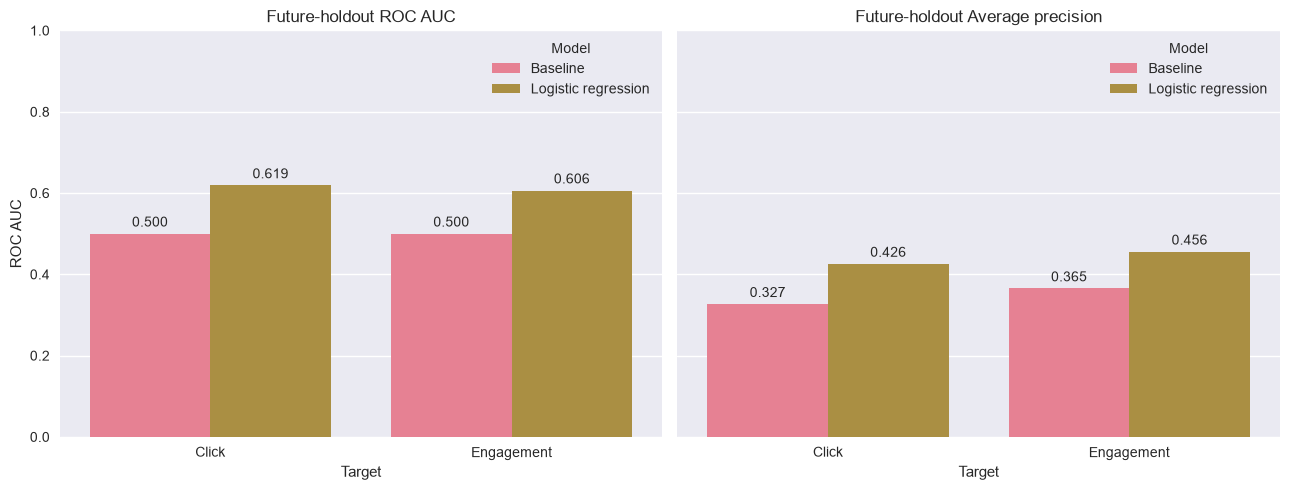

In [12]:
metric_plot = pd.concat(
    [
        click_metrics.assign(target="Click"),
        engagement_metrics.assign(target="Engagement"),
    ]
).reset_index(names="model")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for axis, metric in zip(axes, ["ROC AUC", "Average precision"]):
    sns.barplot(data=metric_plot, x="target", y=metric, hue="model", ax=axis)
    axis.set(title=f"Future-holdout {metric}", xlabel="Target", ylabel=metric, ylim=(0, 1))
    for container in axis.containers:
        axis.bar_label(container, labels=[f"{value:.3f}" for value in container.datavalues], padding=3)
    axis.legend(title="Model")
plt.tight_layout()
plt.show()

The logistic models are compared on the same future period and against prevalence-only baselines.

### Error counts

Use a conventional probability cutoff only to make error tradeoffs visible; policy design will use probabilities directly.

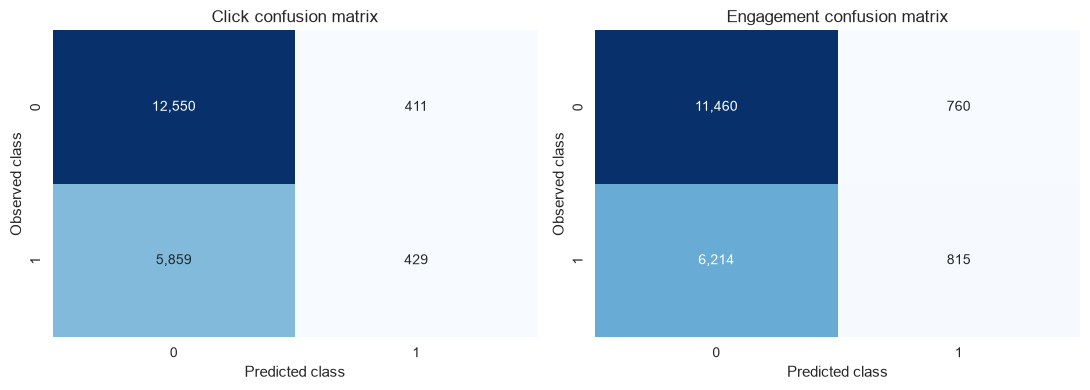

In [13]:
click_matrix = confusion_matrix(click_test, click_score >= 0.5)
engagement_matrix = confusion_matrix(engagement_test, engagement_score >= 0.5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, matrix, title in [
    (axes[0], click_matrix, "Click confusion matrix"),
    (axes[1], engagement_matrix, "Engagement confusion matrix"),
]:
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axis)
    axis.set(title=title, xlabel="Predicted class", ylabel="Observed class")
plt.tight_layout()
plt.show()

A fixed cutoff discards probability information and is not used as the policy objective.

### Engagement model interpretation and feature availability

Only numeric columns are standardized. Category indicators have a different scale, and `preferred_channel` duplicates `channel` on these rows. `baseline_activity_probability` is constant within segment, so individual coefficients from those pairs cannot be assigned standalone importance. The original fitted model is retained for policy reproducibility; the diagnostics below refit a reduced representation and a conservative reconstructible-feature sensitivity model.

,feature,coefficient
25,number__fatigue_sensitivity,-0.035894
17,number__notifications_prior_7d,-0.022618
21,number__hour_local,-0.013677
19,number__fatigue_before_send,-0.011290
22,number__tenure_days_at_start,-0.009670
23,number__baseline_activity_probability,-0.001260
16,number__notifications_prior_24h,0.000000
18,number__notifications_prior_30d,0.011839
20,number__inactive_days_streak,0.017194
14,number__content_relevance,0.168162


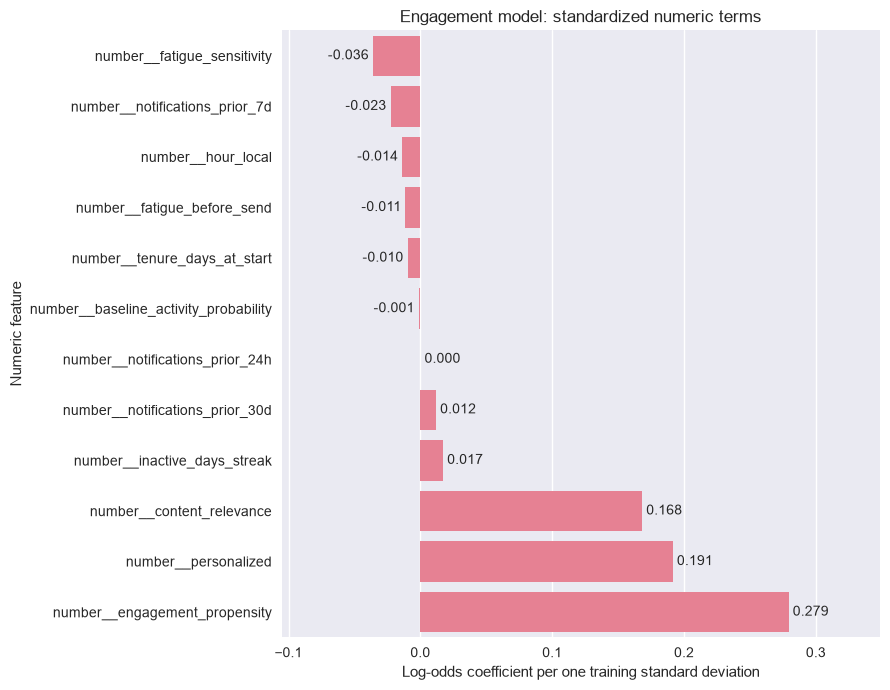

In [14]:
feature_names = engagement_model.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": engagement_model.named_steps["model"].coef_[0],
})
numeric_coefficients = coefficients.loc[
    coefficients["feature"].str.startswith("number__")
].copy().sort_values("coefficient")
display(numeric_coefficients)

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=numeric_coefficients, x="coefficient", y="feature", ax=ax)
ax.margins(x=0.22)  # Keep negative-value annotations clear of the feature labels.
ax.set(title="Engagement model: standardized numeric terms",
       xlabel="Log-odds coefficient per one training standard deviation", ylabel="Numeric feature")
for patch in ax.patches:
    value = patch.get_width()
    ax.annotate(f"{value:.3f}", (value, patch.get_y() + patch.get_height() / 2),
                ha="left" if value >= 0 else "right", va="center",
                xytext=(3 if value >= 0 else -3, 0), textcoords="offset points")
plt.tight_layout()
plt.show()

The plotted terms share a one-training-standard-deviation scale, but correlated features still prevent standalone causal or stable importance interpretations. Category coefficients are omitted from this ranking because they represent one-hot indicators. Predictive sensitivity is evaluated below at the same mature future holdout; it is not a causal decomposition.

In [15]:
# Refit once without two empirically redundant representations.
assert model_data["channel"].eq(model_data["preferred_channel"]).all()
assert model_data.groupby("user_segment")["baseline_activity_probability"].nunique().eq(1).all()
reduced_categorical = [name for name in categorical_features if name != "preferred_channel"]
reduced_numeric = [name for name in numeric_features if name != "baseline_activity_probability"]
reduced_features = reduced_categorical + reduced_numeric
reduced_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("category", OneHotEncoder(handle_unknown="ignore"), reduced_categorical),
        ("number", StandardScaler(), reduced_numeric),
    ])),
    ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
])
reduced_model.fit(model_data.loc[train_mask, reduced_features], engagement_train)
reduced_score = reduced_model.predict_proba(model_data.loc[test_mask, reduced_features])[:, 1]

# Use only candidate metadata and independently reconstructible exposure/time fields.
observable_categorical = ["channel", "notification_type"]
observable_numeric = ["personalized", "notifications_prior_24h", "notifications_prior_7d",
                      "notifications_prior_30d", "hour_local"]
observable_features = observable_categorical + observable_numeric
observable_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("category", OneHotEncoder(handle_unknown="ignore"), observable_categorical),
        ("number", StandardScaler(), observable_numeric),
    ])),
    ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
])
observable_model.fit(model_data.loc[train_mask, observable_features], engagement_train)
observable_score = observable_model.predict_proba(model_data.loc[test_mask, observable_features])[:, 1]

interpretability_metrics = pd.DataFrame({
    "full_original": probability_metrics(engagement_test, engagement_score),
    "reduced_redundancy": probability_metrics(engagement_test, reduced_score),
    "reconstructible_sensitivity": probability_metrics(engagement_test, observable_score),
}).T
print("Mature March engagement holdout; all models fit on the same mature pre-March rows")
display(interpretability_metrics)

import json
phase4_diagnostics = {
    "train_rows": int(train_mask.sum()), "test_rows": int(test_mask.sum()),
    "channel_equals_preferred_channel": True,
    "baseline_probability_constant_within_segment": True,
    "reconstructible_features": observable_features,
    "metrics": {name: {metric: float(value) for metric, value in row.items()}
                for name, row in interpretability_metrics.iterrows()},
}
(project_dir / "data/processed/phase4_model_diagnostics.json").write_text(
    json.dumps(phase4_diagnostics, indent=2) + "\n"
)

Mature March engagement holdout; all models fit on the same mature pre-March rows


,ROC AUC,Average precision,Brier loss
full_original,0.606163,0.455625,0.224381
reduced_redundancy,0.606152,0.455656,0.224381
reconstructible_sensitivity,0.560623,0.404870,0.228945


856

The reduced refit removes the exact channel duplicate and segment-derived baseline probability to test whether their separate coefficients are meaningful. The reconstructible-feature refit omits simulator propensities, unverified fatigue/inactivity histories, tenure, and unverified content-relevance lineage. Its holdout score is a sensitivity result, **not** proof that every field was captured in a live system or that deployment performance would match this synthetic holdout. The original response models and policy scores remain unchanged.

## Question 3: Can the validated event labels support churn modeling?

Check provenance as well as class support. The incomplete activity timeline cannot establish positive churn or an unbiased set of negatives.

In [16]:
known_churn = model_data.loc[model_data["churn_target"].notna(), "churn_target"]
print(f"Evidence-backed negative rows: {len(known_churn):,}")
print(f"Observed classes: {known_churn.nunique():,}")
try:
    churn_training_data(model_data)
except ValueError as error:
    print(error)

Evidence-backed negative rows: 29,775
Observed classes: 1
Churn modeling blocked: incomplete activity history and evidence-selected negatives


The explicit provenance gate blocks churn modeling. Missing labels are never recoded, and future-activity evidence is not used as a predictive feature. Reconstructing the full risk set requires a complete activity log.

## Summary

Print the central holdout results and label limitation.

In [17]:
print(
    f"Click logistic ROC AUC: {click_metrics.loc['Logistic regression', 'ROC AUC']:.4f} "
    f"with 95% CI [{click_auc_ci[0]:.4f}, {click_auc_ci[1]:.4f}]"
)
print(
    f"Engagement logistic ROC AUC: {engagement_metrics.loc['Logistic regression', 'ROC AUC']:.4f} "
    f"with 95% CI [{engagement_auc_ci[0]:.4f}, {engagement_auc_ci[1]:.4f}]"
)
print(f"Observed churn classes: {known_churn.nunique():,}")

import json
model_summary = {"train_rows": int(train_mask.sum()), "test_rows": int(test_mask.sum()),
                 "excluded_incomplete_training": int(excluded_pre_split.sum()),
                 "excluded_incomplete_holdout": int(excluded_final_day.sum()),
                 "click": {k: float(v) for k, v in click_metrics.loc["Logistic regression"].items()},
                 "engagement": {k: float(v) for k, v in engagement_metrics.loc["Logistic regression"].items()},
                 "click_baseline": {k: float(v) for k, v in click_metrics.loc["Baseline"].items()},
                 "engagement_baseline": {k: float(v) for k, v in engagement_metrics.loc["Baseline"].items()}}
(project_dir / "data/processed/phase2_model_metrics.json").write_text(json.dumps(model_summary, indent=2) + "\n")

Click logistic ROC AUC: 0.6188 with 95% CI [0.6102, 0.6281]
Engagement logistic ROC AUC: 0.6062 with 95% CI [0.5977, 0.6155]
Observed churn classes: 1


665

The future holdout supports modest click and engagement prediction. Churn remains unmodelable from the supplied raw target.

## Insights

- Use engagement probabilities as a transparent ranking input, not as proof that sending causes engagement.
- Keep policy rules simple because model discrimination is limited and feature timing is partly assumed.
- Monitor calibration and segment performance before any real deployment.
- Synthetic holdout performance and later policy simulation do not establish real-world causal impact.